### Importing Libraries

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

## Load Dataset

In [7]:
df = pd.read_csv('data.csv') 
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Exploratory Data Analysis(EDA)

In [8]:
df.shape

(1460, 81)

In [9]:
df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [10]:
df.describe

<bound method NDFrame.describe of         Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave   NaN      Reg   
1        2          20       RL         80.0     9600   Pave   NaN      Reg   
2        3          60       RL         68.0    11250   Pave   NaN      IR1   
3        4          70       RL         60.0     9550   Pave   NaN      IR1   
4        5          60       RL         84.0    14260   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave   NaN      Reg   
1456  1457          20       RL         85.0    13175   Pave   NaN      Reg   
1457  1458          70       RL         66.0     9042   Pave   NaN      Reg   
1458  1459          20       RL         68.0     9717   Pave   NaN      Reg   
1459  1460          20       RL         75.0     9937   Pave   NaN      Reg   

     LandContour 

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### Handling Missing Values

##### Checking Missing Values

In [12]:
missing = df.isnull().sum()
missing

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [13]:
missing_val = df.isnull().sum()
missing_val[missing_val>0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

##### Dropping Columns with too many Missing values

In [14]:
df.drop(columns=['Alley','PoolQC','Fence','MiscFeature'],inplace=True)

In [15]:
# Impute with median for the LotFrontage
df['LotFrontage'].fillna(df['LotFrontage'].median(), inplace=True)

In [16]:
# Drop rows with nulls (Simplified Approach)
df.dropna(inplace=True)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 386 entries, 2 to 1456
Data columns (total 77 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             386 non-null    int64  
 1   MSSubClass     386 non-null    int64  
 2   MSZoning       386 non-null    object 
 3   LotFrontage    386 non-null    float64
 4   LotArea        386 non-null    int64  
 5   Street         386 non-null    object 
 6   LotShape       386 non-null    object 
 7   LandContour    386 non-null    object 
 8   Utilities      386 non-null    object 
 9   LotConfig      386 non-null    object 
 10  LandSlope      386 non-null    object 
 11  Neighborhood   386 non-null    object 
 12  Condition1     386 non-null    object 
 13  Condition2     386 non-null    object 
 14  BldgType       386 non-null    object 
 15  HouseStyle     386 non-null    object 
 16  OverallQual    386 non-null    int64  
 17  OverallCond    386 non-null    int64  
 18  YearBuilt     

### Exploratory Data Analysis(EDA)

#### Correlation with SalesPrice

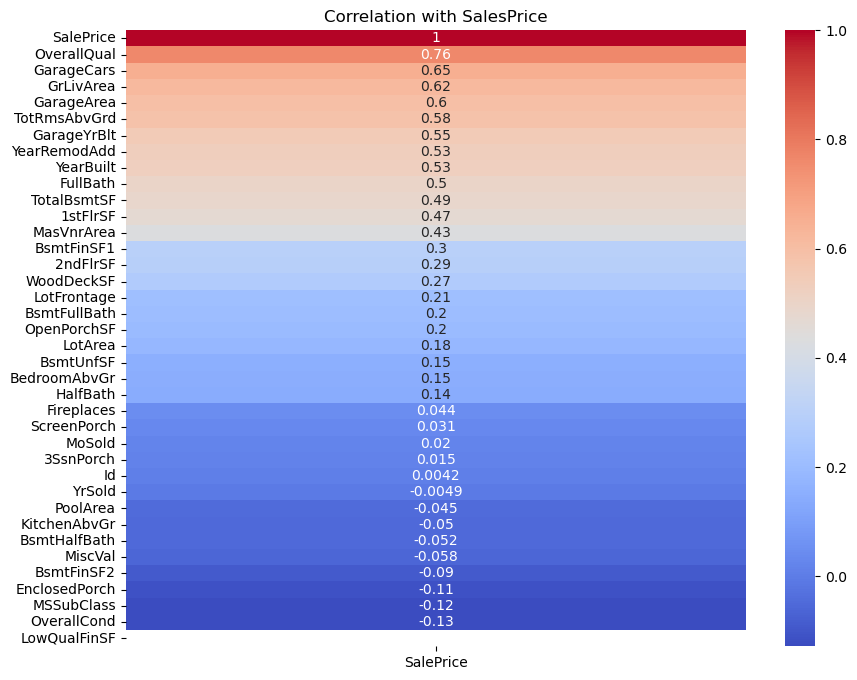

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True)[['SalePrice']].sort_values(by='SalePrice',ascending=False),annot=True,cmap='coolwarm')
plt.title("Correlation with SalesPrice")
plt.show()

#### Distribution of SalePrice

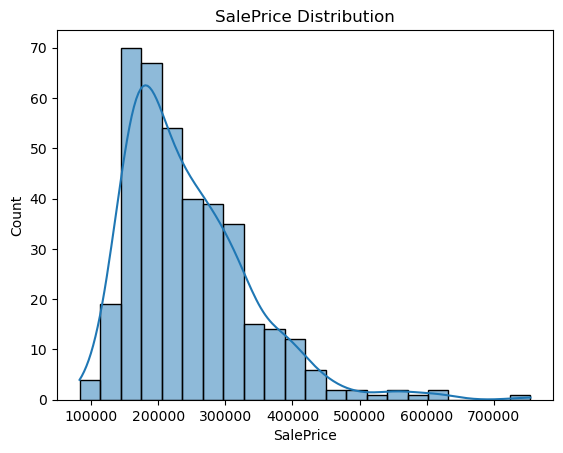

In [20]:
sns.histplot(df['SalePrice'],kde = True)  # SalePrice is right-skewed
plt.title("SalePrice Distribution")
plt.show()

#### Encoding Categorical Variables

In [21]:
#Convert categorical columns into numerical form using one-hot encoding
df_encoded = pd.get_dummies(df,drop_first=True)

In [22]:
df_encoded

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_CWD,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_WD,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,False,True,False,False,True,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,False,True,False,False,True,False
6,7,20,75.0,10084,8,5,2004,2005,186.0,1369,...,False,False,False,False,False,True,False,False,True,False
7,8,60,69.0,10382,7,6,1973,1973,240.0,859,...,False,False,False,False,False,True,False,False,True,False
11,12,60,85.0,11924,9,5,2005,2006,286.0,998,...,False,False,False,False,True,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,1442,120,69.0,4426,6,5,2004,2004,147.0,697,...,False,False,False,False,False,True,False,False,True,False
1442,1443,60,85.0,11003,10,5,2008,2008,160.0,765,...,False,False,False,False,False,True,False,False,True,False
1447,1448,60,80.0,10000,8,5,1995,1996,438.0,1079,...,False,False,False,False,False,True,False,False,True,False
1451,1452,20,78.0,9262,8,5,2008,2009,194.0,0,...,False,False,False,False,True,False,False,False,False,True


- Separating Features (X) and Target(y):

In [23]:
X = df_encoded.drop('SalePrice',axis=1)
y = df_encoded['SalePrice']

In [24]:
X

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_CWD,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_WD,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,False,True,False,False,True,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,False,True,False,False,True,False
6,7,20,75.0,10084,8,5,2004,2005,186.0,1369,...,False,False,False,False,False,True,False,False,True,False
7,8,60,69.0,10382,7,6,1973,1973,240.0,859,...,False,False,False,False,False,True,False,False,True,False
11,12,60,85.0,11924,9,5,2005,2006,286.0,998,...,False,False,False,False,True,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,1442,120,69.0,4426,6,5,2004,2004,147.0,697,...,False,False,False,False,False,True,False,False,True,False
1442,1443,60,85.0,11003,10,5,2008,2008,160.0,765,...,False,False,False,False,False,True,False,False,True,False
1447,1448,60,80.0,10000,8,5,1995,1996,438.0,1079,...,False,False,False,False,False,True,False,False,True,False
1451,1452,20,78.0,9262,8,5,2008,2009,194.0,0,...,False,False,False,False,True,False,False,False,False,True


In [25]:
y

2       223500
4       250000
6       307000
7       200000
11      345000
         ...  
1441    149300
1442    310000
1447    240000
1451    287090
1456    210000
Name: SalePrice, Length: 386, dtype: int64

### Feature Scaling

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [27]:
X

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_CWD,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_WD,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,False,True,False,False,True,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,False,True,False,False,True,False
6,7,20,75.0,10084,8,5,2004,2005,186.0,1369,...,False,False,False,False,False,True,False,False,True,False
7,8,60,69.0,10382,7,6,1973,1973,240.0,859,...,False,False,False,False,False,True,False,False,True,False
11,12,60,85.0,11924,9,5,2005,2006,286.0,998,...,False,False,False,False,True,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,1442,120,69.0,4426,6,5,2004,2004,147.0,697,...,False,False,False,False,False,True,False,False,True,False
1442,1443,60,85.0,11003,10,5,2008,2008,160.0,765,...,False,False,False,False,False,True,False,False,True,False
1447,1448,60,80.0,10000,8,5,1995,1996,438.0,1079,...,False,False,False,False,False,True,False,False,True,False
1451,1452,20,78.0,9262,8,5,2008,2009,194.0,0,...,False,False,False,False,True,False,False,False,False,True


In [28]:
y

2       223500
4       250000
6       307000
7       200000
11      345000
         ...  
1441    149300
1442    310000
1447    240000
1451    287090
1456    210000
Name: SalePrice, Length: 386, dtype: int64

In [29]:
X_scaled

array([[-1.62268375,  0.19352776, -0.43519092, ..., -0.11455723,
         0.54341698, -0.44164062],
       [-1.61799312,  0.19352776,  0.26675192, ..., -0.11455723,
         0.54341698, -0.44164062],
       [-1.61330249, -0.95132609, -0.12809093, ..., -0.11455723,
         0.54341698, -0.44164062],
       ...,
       [ 1.76629473,  0.19352776,  0.09126621, ..., -0.11455723,
         0.54341698, -0.44164062],
       [ 1.77567598, -0.95132609,  0.00352335, ..., -0.11455723,
        -1.8402075 ,  2.26428446],
       [ 1.78740255, -0.95132609,  0.31062335, ..., -0.11455723,
         0.54341698, -0.44164062]])

### Split Dataset into Training and Testing

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [31]:
X_train

array([[ 0.5396956 , -0.95132609,  0.04739478, ..., -0.11455723,
         0.54341698, -0.44164062],
       [ 1.71704314,  0.19352776,  0.13513764, ..., -0.11455723,
         0.54341698, -0.44164062],
       [ 1.62323058,  0.19352776,  0.09126621, ..., -0.11455723,
         0.54341698, -0.44164062],
       ...,
       [ 0.68979568,  0.19352776, -0.3913195 , ..., -0.11455723,
         0.54341698, -0.44164062],
       [ 1.45905862, -0.95132609, -0.74229092, ..., -0.11455723,
         0.54341698, -0.44164062],
       [-0.8674927 ,  0.76595468,  0.79320905, ..., -0.11455723,
         0.54341698, -0.44164062]])

In [32]:
X_test

array([[ 1.35821012,  0.76595468,  2.02160902, ..., -0.11455723,
         0.54341698, -0.44164062],
       [ 1.00875836,  0.76595468, -0.3913195 , ..., -0.11455723,
         0.54341698, -0.44164062],
       [-0.93785211, -0.95132609,  0.09126621, ..., -0.11455723,
         0.54341698, -0.44164062],
       ...,
       [ 1.55052585,  0.76595468,  1.05643761, ..., -0.11455723,
         0.54341698, -0.44164062],
       [-0.22487671, -0.95132609,  0.09126621, ..., -0.11455723,
         0.54341698, -0.44164062],
       [-1.1395491 ,  0.19352776, -0.3913195 , ..., -0.11455723,
         0.54341698, -0.44164062]])

In [33]:
y_train

924     207500
1426    271000
1386    250000
272     290000
780     176000
         ...  
245     241500
347     157500
988     195000
1316    295493
324     242000
Name: SalePrice, Length: 308, dtype: int64

In [34]:
y_test

1273    177000
1124    163900
294     167000
961     272000
527     446261
         ...  
58      438780
476     208900
1355    170000
598     217500
208     277000
Name: SalePrice, Length: 78, dtype: int64

In [35]:
X_train.shape

(308, 181)

In [36]:
X_test.shape

(78, 181)

In [37]:
y_test.shape

(78,)

In [38]:
y_train.shape

(308,)

## Model Building

#### 1.Random Forest

In [39]:
rf = RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(X_train,y_train)
y_pred_rf = rf.predict(X_test)

In [40]:
y_pred_rf

array([152671.17, 174965.9 , 165962.6 , 232147.7 , 393184.96, 160708.74,
       330215.71, 256025.23, 165899.5 , 202294.  , 286413.41, 378436.69,
       251402.17, 162005.  , 292185.31, 196675.74, 259681.75, 231089.5 ,
       366765.64, 173733.9 , 212317.24, 307040.72, 162953.11, 244755.86,
       373266.33, 164516.5 , 281264.39, 266055.34, 316682.7 , 224552.91,
       180718.4 , 221375.8 , 252653.65, 148358.37, 345613.7 , 361747.96,
       426690.49, 343172.78, 170494.  , 174841.87, 219835.1 , 181230.  ,
       322754.51, 388035.74, 214351.72, 373422.24, 262368.1 , 197207.3 ,
       212515.05, 183803.74, 200349.8 , 147715.74, 159332.87, 281509.61,
       193807.  , 178014.4 , 138428.37, 500987.17, 393381.15, 328288.93,
       168354.  , 325242.06, 339758.58, 207258.79, 234477.09, 339887.32,
       311396.28, 207816.38, 239511.97, 157777.5 , 186627.46, 152763.  ,
       199747.4 , 332058.9 , 196288.48, 203732.  , 202192.25, 229617.4 ])

In [41]:
y_test

1273    177000
1124    163900
294     167000
961     272000
527     446261
         ...  
58      438780
476     208900
1355    170000
598     217500
208     277000
Name: SalePrice, Length: 78, dtype: int64

#### 2.XGBoost

In [42]:
xgb = XGBRegressor(n_estimators = 100,learning_rate=0.1)
xgb.fit(X_train,y_train)
y_pred_xgb = xgb.predict(X_test)

In [43]:
y_pred_xgb

array([162286.83, 170696.2 , 165501.8 , 223065.42, 408410.53, 167258.72,
       358519.12, 262687.16, 176046.61, 203586.1 , 286356.03, 397059.78,
       252399.28, 156965.44, 301547.47, 192532.7 , 265500.25, 250690.53,
       389991.66, 174965.73, 216857.14, 312221.47, 165057.84, 225422.89,
       366125.62, 159166.36, 300848.28, 256930.55, 328962.7 , 223193.08,
       181236.81, 230675.16, 256578.48, 139425.28, 385895.7 , 291707.47,
       400762.88, 358987.75, 164529.08, 164265.81, 210899.52, 170904.84,
       376518.2 , 397871.75, 220291.56, 377096.72, 227452.36, 190385.19,
       228044.72, 191100.56, 209407.72, 133827.08, 156225.4 , 283104.25,
       194785.42, 184003.1 , 145730.39, 512891.1 , 347301.28, 316137.25,
       160112.9 , 333955.2 , 329322.06, 208945.64, 244501.19, 350492.38,
       370128.22, 226673.78, 231123.98, 156594.42, 192101.14, 152920.58,
       210004.27, 371503.38, 191451.97, 213518.39, 213278.92, 247689.34],
      dtype=float32)

In [44]:
y_test

1273    177000
1124    163900
294     167000
961     272000
527     446261
         ...  
58      438780
476     208900
1355    170000
598     217500
208     277000
Name: SalePrice, Length: 78, dtype: int64

### Model Evaluation

In [45]:
def print_metrics(y_true, y_pred, model_name):
    print(f"{model_name} Performance:")
    print("R2 Score:", r2_score(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("-" * 30)

print_metrics(y_test, y_pred_rf, "Random Forest")
print_metrics(y_test, y_pred_xgb, "XGBoost")

Random Forest Performance:
R2 Score: 0.8193179740055279
RMSE: 41380.1550708139
------------------------------
XGBoost Performance:
R2 Score: 0.7970593571662903
RMSE: 43855.00327214673
------------------------------


### Model Comparision with Cross-Validation

In [46]:
models = {
    "Random Forest": rf,
    "XGBoost": xgb
}

for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')
    print(f"{name} Average R2 Score: {scores.mean():.4f}")

Random Forest Average R2 Score: 0.7677
XGBoost Average R2 Score: 0.7788


### Customers Suggestion(Based on Data Insights)

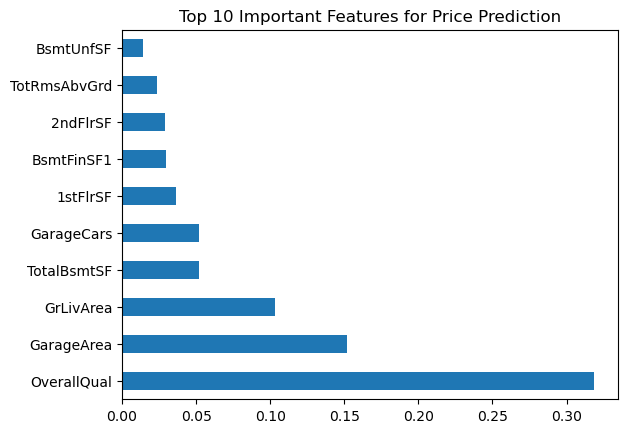

In [47]:
# Top important features from Random Forest
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
feat_imp.nlargest(10).plot(kind='barh')
plt.title("Top 10 Important Features for Price Prediction")
plt.show()

#### Suggestions
- Focus on properties with higher OverallQual, TotalBsmtSF, and GrLivArea as they strongly influence house prices
- Consider location-related features (Neighborhood, proximity to amenities) for better price estimation
- Proper feature scaling and transformation improves model performance

### Challenges Faced
##### Challenges:
- Presence of many missing values in columns such as LotFrontage, Alley, FireplaceQu
- Large number of categorical variables requiring encoding
- Skewed target variable (SalePrice) affecting model accuracy
- Outliers in features like GrLivArea and SalePrice
##### Solutions:
- Handled missing values using mean/median/mode imputation
- Applied one-hot encoding for categorical features
- Used log transformation to reduce SalePrice skewness
- Removed or treated extreme outliers for stability